In [6]:
# experiment decision tree 

# load the dataset 
import numpy as np

saved_data = np.load('../processed/rt_iot2022_model_data.npz', allow_pickle=True)

saved_data.files

# Extract the saved arrays
X_train_final = saved_data['X_train_final']
X_test_final = saved_data['X_test_final']

y_train = saved_data['y_train']
y_test = saved_data['y_test']

feature_names = saved_data['feature_names']

In [7]:
# Check dimensions
print("Training features:", X_train_final.shape)
print("Testing features:", X_test_final.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Number of features:", len(feature_names))

# Check attack categories and their counts
categories, counts = np.unique(y_train, return_counts=True)

print("\nAttack categories in training data:")
for category, count in zip(categories, counts):
    print(category, ":", count)

print("\nTotal categories:", len(categories))

Training features: (98493, 93)
Testing features: (24624, 93)
Training labels: (98493,)
Testing labels: (24624,)
Number of features: 93

Attack categories in training data:
ARP_poisioning : 6200
DDOS_Slowloris : 427
DOS_SYN_Hping : 75727
MQTT_Publish : 3317
Metasploit_Brute_Force_SSH : 30
NMAP_FIN_SCAN : 22
NMAP_OS_DETECTION : 1600
NMAP_TCP_scan : 802
NMAP_UDP_SCAN : 2072
NMAP_XMAS_TREE_SCAN : 1608
Thing_Speak : 6486
Wipro_bulb : 202

Total categories: 12


In [8]:
# Split into training and validation sets

from sklearn.model_selection import train_test_split

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_final,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Model training data:", X_model_train.shape)
print("Validation data:", X_val.shape)

print("Model training labels:", y_model_train.shape)
print("Validation labels:", y_val.shape)

Model training data: (78794, 93)
Validation data: (19699, 93)
Model training labels: (78794,)
Validation labels: (19699,)


In [9]:
# Evaluate the model
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [10]:
# Train decision tree model

from sklearn.tree import DecisionTreeClassifier

# Initialise the Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_model_train, y_model_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [11]:
# Make predictions

y_pred_dt = dt_model.predict(X_val)

In [12]:
# Check accuracy of decision tree 


from sklearn.metrics import accuracy_score, f1_score, classification_report

# Accuracy
print("Accuracy:", accuracy_score(y_val, y_pred_dt))

# Macro F1 Score
print("Macro F1:", f1_score(y_val, y_pred_dt, average='macro', zero_division=0))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_val, y_pred_dt, zero_division=0))

Accuracy: 0.9970556881059952
Macro F1: 0.9586731728729934

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.98      0.98      1240
            DDOS_Slowloris       1.00      0.98      0.99        85
             DOS_SYN_Hping       1.00      1.00      1.00     15146
              MQTT_Publish       1.00      1.00      1.00       664
Metasploit_Brute_Force_SSH       0.83      0.83      0.83         6
             NMAP_FIN_SCAN       0.75      0.75      0.75         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       320
             NMAP_TCP_scan       1.00      1.00      1.00       160
             NMAP_UDP_SCAN       0.99      0.98      0.98       415
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       322
               Thing_Speak       0.98      0.98      0.98      1297
                Wipro_bulb       1.00      0.97      0.99        40

                  accuracy      

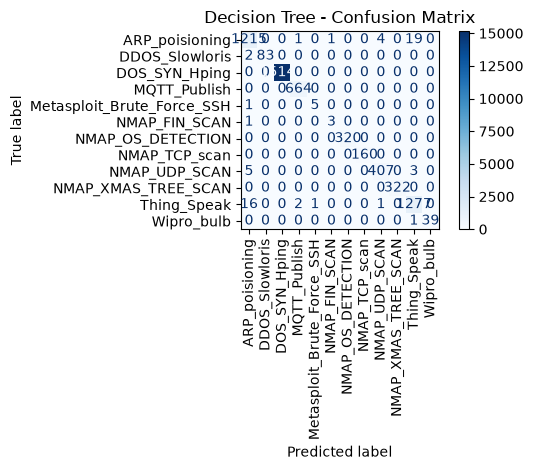

In [13]:
# accuracy again by confusion matrix this time

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_dt,
    xticks_rotation='vertical',
    cmap='Blues'
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

In [14]:
# Call and set up and train Random Forest model

from sklearn.ensemble import RandomForestClassifier

# Initialise Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_model_train, y_model_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [15]:
y_pred_rf = rf_model.predict(X_val)

# Prediction

In [16]:
#Accuracy check for Random Forest 

print("Accuracy:", accuracy_score(y_val, y_pred_rf))

print("Macro F1:", f1_score(
    y_val, y_pred_rf,
    average='macro',
    zero_division=0
))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf, zero_division=0))

Accuracy: 0.9980709680694452
Macro F1: 0.9717502867632938

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.99      0.99      1240
            DDOS_Slowloris       0.98      0.96      0.97        85
             DOS_SYN_Hping       1.00      1.00      1.00     15146
              MQTT_Publish       1.00      1.00      1.00       664
Metasploit_Brute_Force_SSH       1.00      0.83      0.91         6
             NMAP_FIN_SCAN       1.00      0.75      0.86         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       320
             NMAP_TCP_scan       1.00      1.00      1.00       160
             NMAP_UDP_SCAN       0.99      0.98      0.98       415
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       322
               Thing_Speak       0.99      0.99      0.99      1297
                Wipro_bulb       1.00      0.93      0.96        40

                  accuracy      

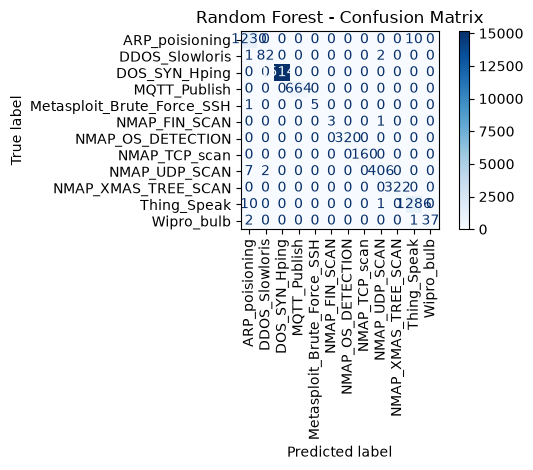

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    xticks_rotation='vertical',
    cmap='Blues'
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

#Confusion matrix for Random Forest 

In [18]:
from sklearn.metrics import balanced_accuracy_score

print("Decision Tree Balanced Accuracy:",
      balanced_accuracy_score(y_val, y_pred_dt))

print("Random Forest Balanced Accuracy:",
      balanced_accuracy_score(y_val, y_pred_rf))

Decision Tree Balanced Accuracy: 0.9566621101958087
Random Forest Balanced Accuracy: 0.9529005701929049


In [19]:
# Testing the selected model Random Forest of untouched test data 

# Predict using the test dataset
y_pred_rf_test = rf_model.predict(X_test_final)

# Calculate Accuracy
print("Test Accuracy:",
      accuracy_score(y_test, y_pred_rf_test))

# Calculate Macro F1
print("Test Macro F1:",
      f1_score(y_test, y_pred_rf_test,
               average='macro',
               zero_division=0))

# Calculate Balanced Accuracy
print("Test Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred_rf_test))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf_test,
    zero_division=0
))

Test Accuracy: 0.9982537361923327
Test Macro F1: 0.962245230888569
Test Balanced Accuracy: 0.9656589852886716

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       0.98      0.97      0.98       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.75      0.86      0.80         7
             NMAP_FIN_SCAN       0.83      0.83      0.83         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      0.99      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       0.98      0.96  

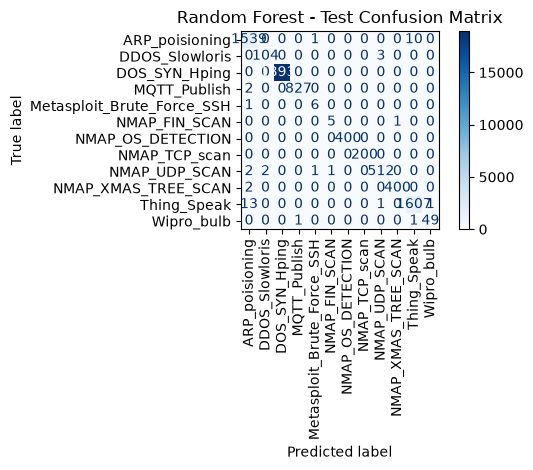

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf_test,
    xticks_rotation='vertical',
    cmap='Blues'
)

plt.title("Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.show()

Observations selected for SHAP: 500
SHAP values calculated successfully.

TOP 20 GLOBALLY IMPORTANT FEATURES:


,Feature,Mean_Absolute_SHAP
1,id.resp_p,0.007163
29,fwd_pkts_payload.avg,0.006814
26,fwd_pkts_payload.min,0.006115
27,fwd_pkts_payload.max,0.004685
59,fwd_subflow_bytes,0.004339
28,fwd_pkts_payload.tot,0.003518
83,service_-,0.003475
51,flow_iat.min,0.002495
70,active.avg,0.002475
2,flow_duration,0.002438


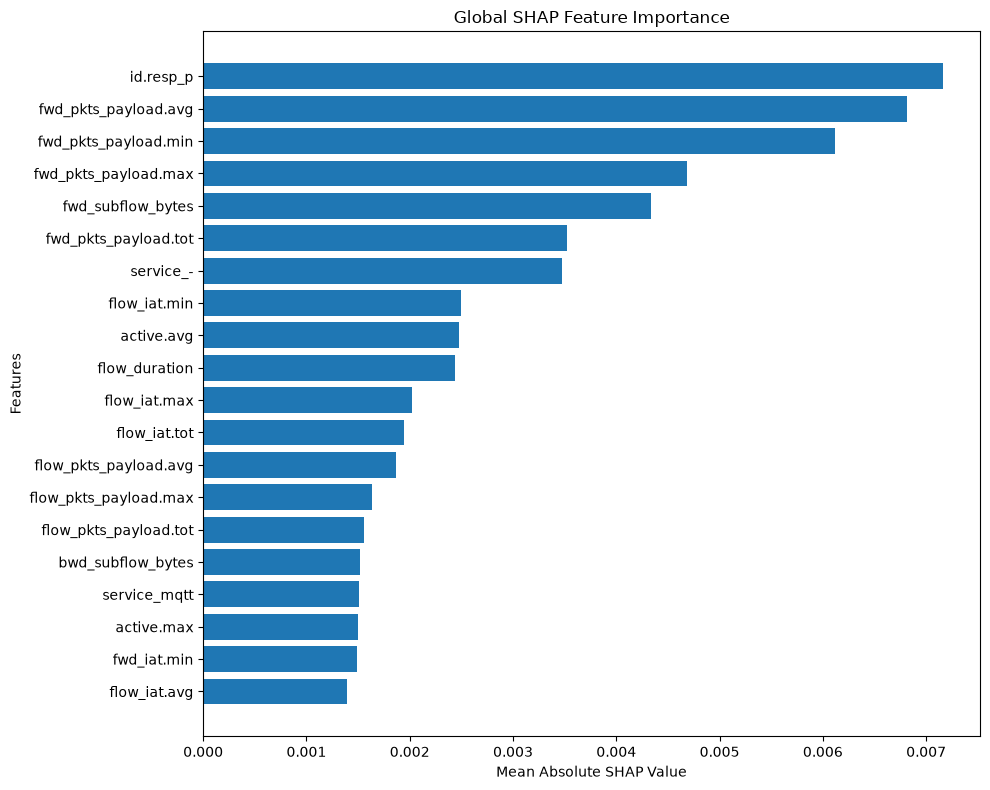

c:\Users\Aditya\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(



CLASS SELECTED FOR FEATURE IMPACT: DOS_SYN_Hping


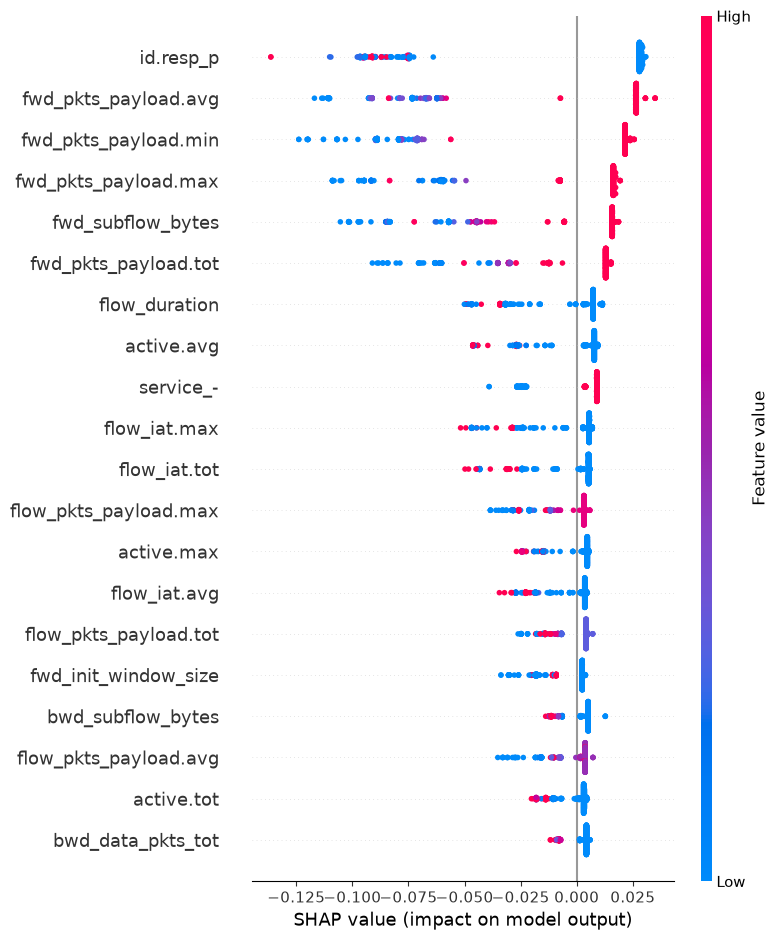


LOCAL EXPLANATION
Observation index: 0
Actual category: DOS_SYN_Hping
Predicted category: DOS_SYN_Hping


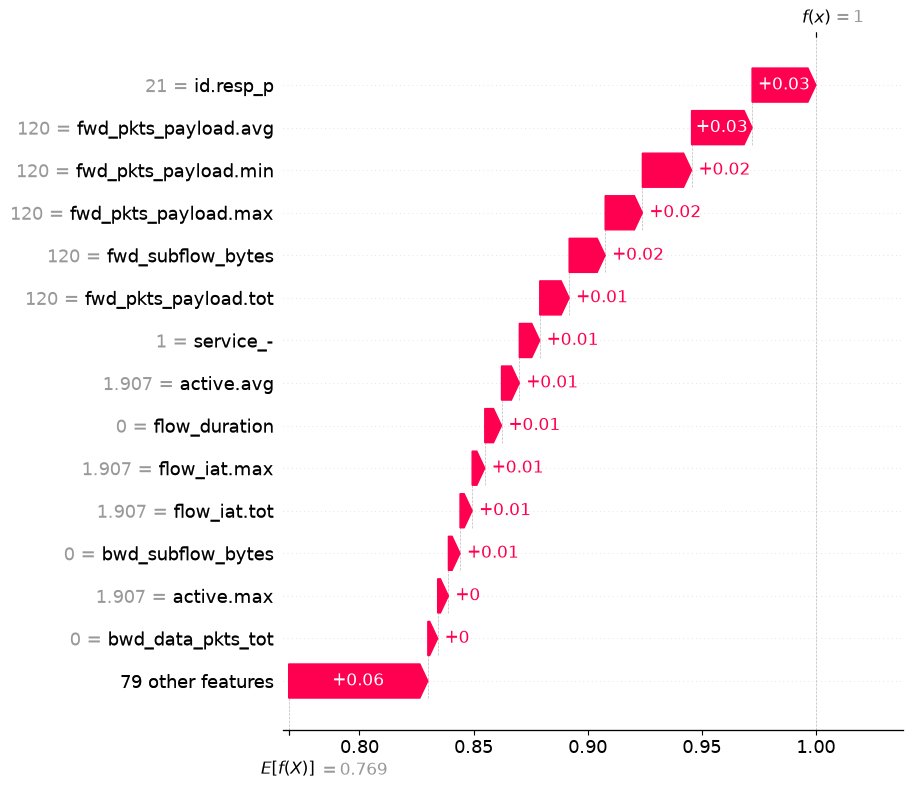


SHAP EXPLAINABILITY EXPERIMENT COMPLETED.


In [21]:

# ==========================================
# SHADOWSCAN PHASE 1: SHAP EXPLAINABILITY - 500 observations only tech layer 
# ==========================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Select a sample of validation observations
n_samples = min(500, len(X_val))

X_shap = pd.DataFrame(
    X_val[:n_samples],
    columns=feature_names
)

y_shap_true = np.asarray(y_val)[:n_samples]

print("Observations selected for SHAP:", n_samples)

# 2. Initialise TreeExplainer using our trained Random Forest
explainer = shap.TreeExplainer(rf_model)

# 3. Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully.")

# 4. Handle multiclass SHAP output
# Different SHAP versions return slightly different formats.

if isinstance(shap_values, list):
    # Older SHAP versions: one array per class
    class_shap_values = shap_values
else:
    # Newer SHAP versions: samples x features x classes
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        class_shap_values = [
            shap_array[:, :, i]
            for i in range(shap_array.shape[2])
        ]
    else:
        class_shap_values = [shap_array]

# 5. GLOBAL EXPLANATION
# Calculate average absolute SHAP contribution
# across observations and all output classes.

global_importance = np.mean(
    np.abs(np.stack(class_shap_values, axis=2)),
    axis=(0, 2)
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": global_importance
}).sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("\nTOP 20 GLOBALLY IMPORTANT FEATURES:")
display(importance_df.head(20))

# Plot global feature importance
plt.figure(figsize=(10, 8))

top_features = importance_df.head(20).sort_values(
    "Mean_Absolute_SHAP"
)

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

# 6. CLASS-SPECIFIC FEATURE IMPACT
# Select the most frequently predicted class
# in our SHAP sample.

y_shap_pred = rf_model.predict(X_shap)

target_class = pd.Series(y_shap_pred).mode().iloc[0]

classes = np.asarray(rf_model.classes_)
class_idx = np.where(classes == target_class)[0][0]

print("\nCLASS SELECTED FOR FEATURE IMPACT:", target_class)

shap.summary_plot(
    class_shap_values[class_idx],
    X_shap,
    plot_type="dot",
    max_display=20
)

# 7. LOCAL EXPLANATION
# Find one correctly classified observation.
# If none exists in this sample, use the first observation.

correct_indices = np.where(
    y_shap_true == y_shap_pred
)[0]

if len(correct_indices) > 0:
    local_idx = correct_indices[0]
else:
    local_idx = 0

actual_class = y_shap_true[local_idx]
predicted_class = y_shap_pred[local_idx]

local_class_idx = np.where(
    classes == predicted_class
)[0][0]

print("\nLOCAL EXPLANATION")
print("Observation index:", local_idx)
print("Actual category:", actual_class)
print("Predicted category:", predicted_class)

# Extract the baseline value for the predicted class
base_values = np.asarray(explainer.expected_value)

if base_values.ndim == 0:
    local_base_value = float(base_values)
else:
    local_base_value = float(
        base_values.flatten()[local_class_idx]
    )

# Create a SHAP Explanation object
local_explanation = shap.Explanation(
    values=class_shap_values[local_class_idx][local_idx],
    base_values=local_base_value,
    data=X_shap.iloc[local_idx].values,
    feature_names=feature_names
)

# Waterfall plot: contribution of individual features
shap.plots.waterfall(
    local_explanation,
    max_display=15
)

print("\nSHAP EXPLAINABILITY EXPERIMENT COMPLETED.")


SHADOWSCAN XAI EXPERIMENT

Observations analysed: 5000

CLASS DISTRIBUTION:
DOS_SYN_Hping                 3844
Thing_Speak                    329
ARP_poisioning                 315
MQTT_Publish                   169
NMAP_UDP_SCAN                  105
NMAP_XMAS_TREE_SCAN             82
NMAP_OS_DETECTION               81
NMAP_TCP_scan                   41
DDOS_Slowloris                  22
Wipro_bulb                      10
Metasploit_Brute_Force_SSH       1
NMAP_FIN_SCAN                    1
Name: count, dtype: int64

SHAP calculation completed.


c:\Users\Aditya\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(



GLOBAL FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
1,id.resp_p,0.007290
29,fwd_pkts_payload.avg,0.006891
26,fwd_pkts_payload.min,0.006233
27,fwd_pkts_payload.max,0.004709
59,fwd_subflow_bytes,0.004401
28,fwd_pkts_payload.tot,0.003602
83,service_-,0.003436
70,active.avg,0.002527
51,flow_iat.min,0.002525
2,flow_duration,0.002503


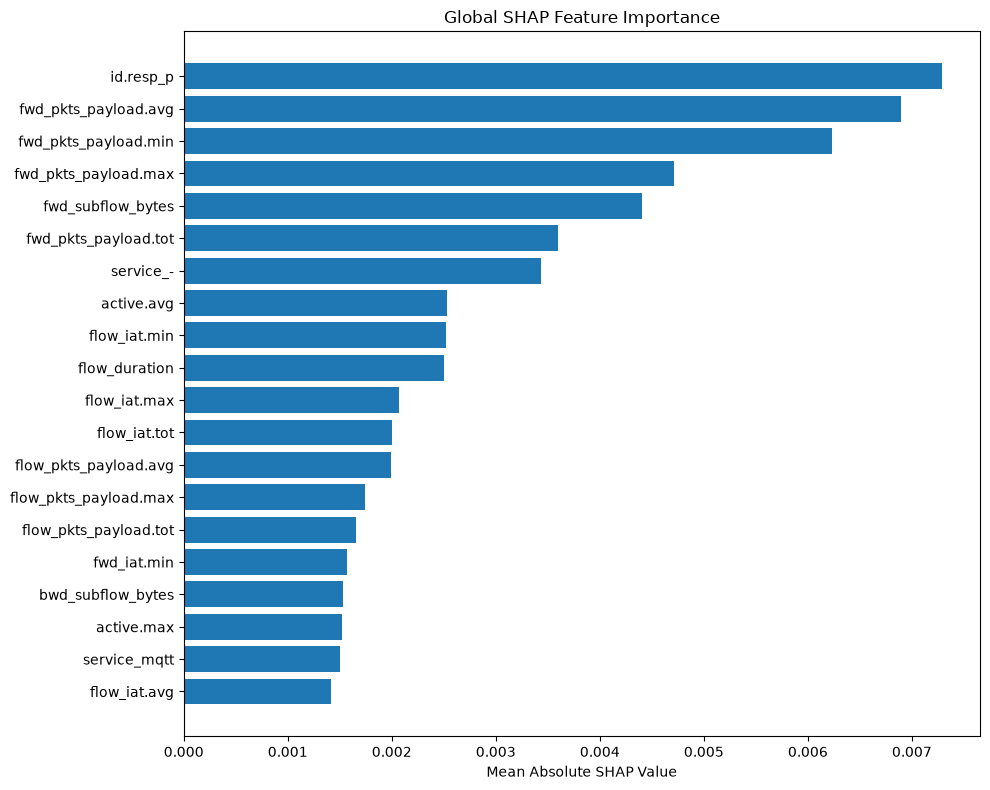


CLASS-SPECIFIC EXPLANATION
Selected category: DOS_SYN_Hping


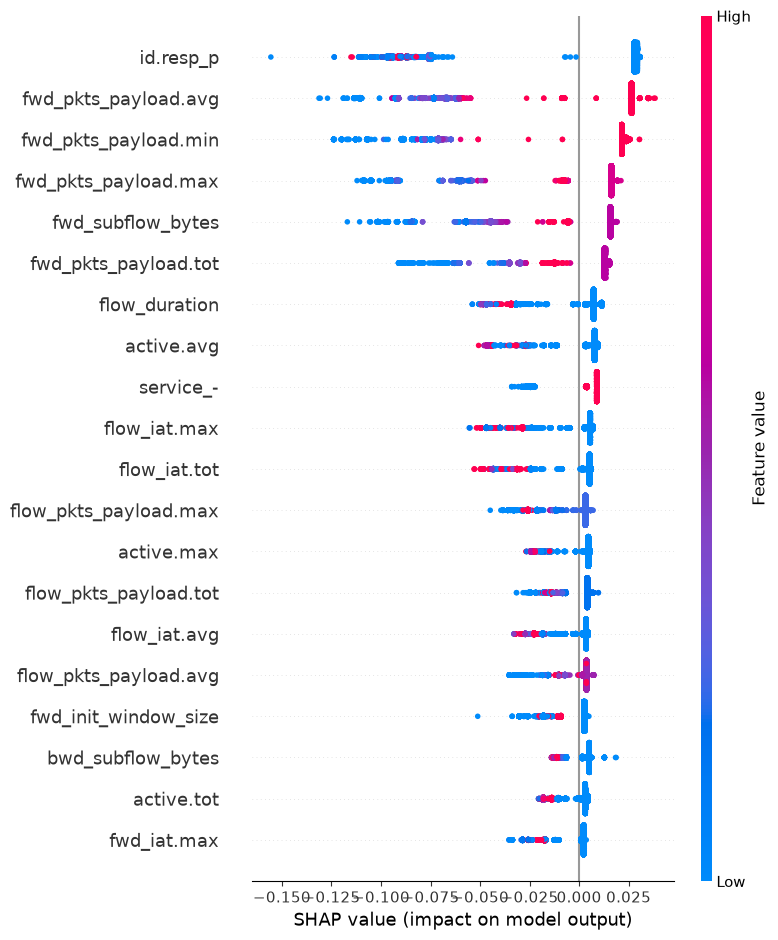


TECHNICAL LOCAL EXPLANATION
Observation: 0
Actual category: DOS_SYN_Hping
Predicted category: DOS_SYN_Hping


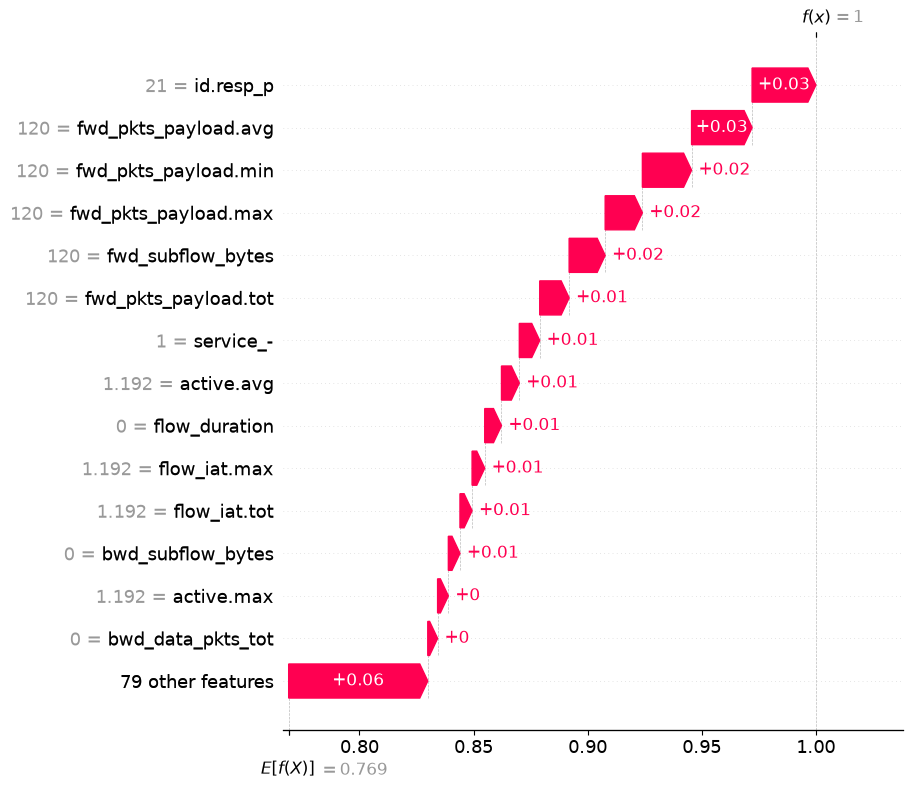


SHADOWSCAN - PLAIN ENGLISH EXPLANATION

1. WHAT DID THE MODEL PREDICT?
The model classified this network observation as DOS_SYN_Hping.
The prediction matches the actual dataset label.

2. WHICH FEATURES SUPPORTED THE PREDICTION?
- Destination port (id.resp_p), value: 21.0000, SHAP contribution: +0.02796
- Average forward packet payload size (fwd_pkts_payload.avg), value: 120.0000, SHAP contribution: +0.02652
- Minimum forward packet payload size (fwd_pkts_payload.min), value: 120.0000, SHAP contribution: +0.02156
- Maximum forward packet payload size (fwd_pkts_payload.max), value: 120.0000, SHAP contribution: +0.01631
- Bytes transferred in forward subflows (fwd_subflow_bytes), value: 120.0000, SHAP contribution: +0.01579

3. WHICH FEATURES OPPOSED THE PREDICTION?
No negative feature contributions found.

4. WHAT DOES THIS MEAN?
The listed features influenced the model's decision towards or away from the predicted category.
These are model-level feature contributions, not proof of mal

In [23]:
# 5000 observations human + tech layer 


# ==========================================================
# SHADOWSCAN PHASE 1: XAI + SHAP EXPLAINABILITY
# Human-readable explanations + Technical analysis
# ==========================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# ----------------------------------------------------------
# 1. SELECT 5000 STRATIFIED VALIDATION OBSERVATIONS
# ----------------------------------------------------------

n_samples = min(5000, len(X_val))

all_indices = np.arange(len(y_val))

if n_samples < len(all_indices):
    shap_indices, _ = train_test_split(
        all_indices,
        train_size=n_samples,
        stratify=y_val,
        random_state=42
    )
else:
    shap_indices = all_indices

X_shap = pd.DataFrame(
    X_val[shap_indices],
    columns=feature_names
)

y_shap_true = np.asarray(y_val)[shap_indices]

print("=" * 60)
print("SHADOWSCAN XAI EXPERIMENT")
print("=" * 60)

print("\nObservations analysed:", len(X_shap))

print("\nCLASS DISTRIBUTION:")
print(pd.Series(y_shap_true).value_counts())

# ----------------------------------------------------------
# 2. INITIALISE TREE EXPLAINER
# ----------------------------------------------------------

explainer = shap.TreeExplainer(rf_model)

# ----------------------------------------------------------
# 3. CALCULATE SHAP VALUES
# ----------------------------------------------------------

shap_values = explainer.shap_values(X_shap)

# Handle different SHAP version output formats

if isinstance(shap_values, list):

    class_shap_values = shap_values

else:

    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:

        if shap_array.shape[0] == len(X_shap):
            class_shap_values = [
                shap_array[:, :, i]
                for i in range(shap_array.shape[2])
            ]

        elif shap_array.shape[1] == len(X_shap):
            class_shap_values = [
                shap_array[i, :, :]
                for i in range(shap_array.shape[0])
            ]

        else:
            raise ValueError("Unexpected SHAP array dimensions.")

    else:
        class_shap_values = [shap_array]

print("\nSHAP calculation completed.")

# ----------------------------------------------------------
# 4. GENERATE MODEL PREDICTIONS
# ----------------------------------------------------------

y_shap_pred = rf_model.predict(X_shap)

class_names = np.asarray(rf_model.classes_)

# ----------------------------------------------------------
# 5. GLOBAL FEATURE IMPORTANCE
# ----------------------------------------------------------

all_class_values = np.stack(
    class_shap_values,
    axis=2
)

global_importance = np.mean(
    np.abs(all_class_values),
    axis=(0, 2)
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": global_importance
}).sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("\n" + "=" * 60)
print("GLOBAL FEATURE IMPORTANCE")
print("=" * 60)

display(importance_df.head(20))

# Global importance plot

top_features = importance_df.head(20).sort_values(
    "Mean_Absolute_SHAP"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 6. CLASS-SPECIFIC EXPLANATION
# ----------------------------------------------------------

target_class = pd.Series(y_shap_pred).mode().iloc[0]

class_idx = np.where(class_names == target_class)[0][0]

print("\n" + "=" * 60)
print("CLASS-SPECIFIC EXPLANATION")
print("=" * 60)

print("Selected category:", target_class)

shap.summary_plot(
    class_shap_values[class_idx],
    X_shap,
    plot_type="dot",
    max_display=20
)

# ----------------------------------------------------------
# 7. SELECT ONE OBSERVATION FOR LOCAL EXPLANATION
# ----------------------------------------------------------

correct_indices = np.where(
    y_shap_true == y_shap_pred
)[0]

incorrect_indices = np.where(
    y_shap_true != y_shap_pred
)[0]

# Select a correctly classified observation for now

if len(correct_indices) > 0:
    local_idx = correct_indices[0]
else:
    local_idx = 0

actual_class = y_shap_true[local_idx]
predicted_class = y_shap_pred[local_idx]

local_class_idx = np.where(
    class_names == predicted_class
)[0][0]

local_values = class_shap_values[local_class_idx][local_idx]

# ----------------------------------------------------------
# 8. TECHNICAL LOCAL EXPLANATION
# ----------------------------------------------------------

base_values = np.asarray(explainer.expected_value)

if base_values.ndim == 0:
    local_base_value = float(base_values)
else:
    local_base_value = float(
        base_values.flatten()[local_class_idx]
    )

local_explanation = shap.Explanation(
    values=local_values,
    base_values=local_base_value,
    data=X_shap.iloc[local_idx].values,
    feature_names=feature_names
)

print("\n" + "=" * 60)
print("TECHNICAL LOCAL EXPLANATION")
print("=" * 60)

print("Observation:", local_idx)
print("Actual category:", actual_class)
print("Predicted category:", predicted_class)

shap.plots.waterfall(
    local_explanation,
    max_display=15
)

# ----------------------------------------------------------
# 9. HUMAN-READABLE EXPLANATION
# ----------------------------------------------------------

feature_descriptions = {
    "id.resp_p": "Destination port",
    "fwd_pkts_payload.avg": "Average forward packet payload size",
    "fwd_pkts_payload.min": "Minimum forward packet payload size",
    "fwd_pkts_payload.max": "Maximum forward packet payload size",
    "fwd_pkts_payload.tot": "Total forward packet payload",
    "fwd_subflow_bytes": "Bytes transferred in forward subflows",
    "bwd_subflow_bytes": "Bytes transferred in backward subflows",
    "flow_duration": "Duration of the network flow",
    "flow_iat.min": "Minimum time between consecutive flow packets",
    "flow_iat.max": "Maximum time between consecutive flow packets",
    "flow_iat.avg": "Average time between consecutive flow packets",
    "flow_iat.tot": "Total flow inter-arrival time",
    "active.avg": "Average active time of the flow",
    "active.max": "Maximum active time of the flow",
    "service_-": "Encoded service category: unspecified",
    "service_mqtt": "Encoded service category: MQTT"
}

local_features = X_shap.iloc[local_idx]

# Sort feature contributions from highest to lowest

sorted_indices = np.argsort(np.abs(local_values))[::-1]

positive_features = [
    i for i in sorted_indices if local_values[i] > 0
][:5]

negative_features = [
    i for i in sorted_indices if local_values[i] < 0
][:5]

print("\n" + "=" * 60)
print("SHADOWSCAN - PLAIN ENGLISH EXPLANATION")
print("=" * 60)

print("\n1. WHAT DID THE MODEL PREDICT?")

print(
    f"The model classified this network observation as "
    f"{predicted_class}."
)

if actual_class == predicted_class:
    print("The prediction matches the actual dataset label.")
else:
    print(
        f"WARNING: The actual category was {actual_class}. "
        "The model made an incorrect prediction."
    )

print("\n2. WHICH FEATURES SUPPORTED THE PREDICTION?")

if positive_features:

    for i in positive_features:

        feature = feature_names[i]

        description = feature_descriptions.get(
            feature, feature
        )

        print(
            f"- {description} ({feature}), "
            f"value: {local_features.iloc[i]:.4f}, "
            f"SHAP contribution: +{local_values[i]:.5f}"
        )

else:
    print("No positive feature contributions found.")

print("\n3. WHICH FEATURES OPPOSED THE PREDICTION?")

if negative_features:

    for i in negative_features:

        feature = feature_names[i]

        description = feature_descriptions.get(
            feature, feature
        )

        print(
            f"- {description} ({feature}), "
            f"value: {local_features.iloc[i]:.4f}, "
            f"SHAP contribution: {local_values[i]:.5f}"
        )

else:
    print("No negative feature contributions found.")

print("\n4. WHAT DOES THIS MEAN?")

print(
    "The listed features influenced the model's decision "
    "towards or away from the predicted category."
)

print(
    "These are model-level feature contributions, "
    "not proof of malicious activity or causation."
)

# ----------------------------------------------------------
# 10. EXPERIMENT SUMMARY
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("XAI EXPERIMENT SUMMARY")
print("=" * 60)

print("Observations analysed:", len(X_shap))
print("Features analysed:", len(feature_names))
print("Traffic categories:", len(class_names))
print("Correct predictions in sample:", len(correct_indices))
print("Incorrect predictions in sample:", len(incorrect_indices))

print("\nSHADOWSCAN XAI ANALYSIS COMPLETED.")


In [24]:

# ==================================================
# SHADOWSCAN: MISCLASSIFICATION INVESTIGATION
# ==================================================

# Find incorrect predictions
incorrect_indices = np.where(
    y_shap_true != y_shap_pred
)[0]

print("Total incorrect predictions:", len(incorrect_indices))

# Create a table of incorrect predictions
error_records = []

for idx in incorrect_indices:

    error_records.append({
        "Observation": int(idx),
        "Actual Category": y_shap_true[idx],
        "Predicted Category": y_shap_pred[idx]
    })

error_df = pd.DataFrame(error_records)

print("\nMISCLASSIFIED OBSERVATIONS:")
display(error_df)

# Count the types of misclassification
print("\nMISCLASSIFICATION PATTERNS:")

display(
    error_df.groupby(
        ["Actual Category", "Predicted Category"]
    ).size().reset_index(name="Count")
)


Total incorrect predictions: 10

MISCLASSIFIED OBSERVATIONS:


,Observation,Actual Category,Predicted Category
0,565,Thing_Speak,ARP_poisioning
1,1745,NMAP_UDP_SCAN,ARP_poisioning
2,1821,DDOS_Slowloris,NMAP_UDP_SCAN
3,2155,Thing_Speak,ARP_poisioning
4,2703,ARP_poisioning,Thing_Speak
5,3886,Wipro_bulb,ARP_poisioning
6,4344,NMAP_UDP_SCAN,ARP_poisioning
7,4351,NMAP_FIN_SCAN,NMAP_UDP_SCAN
8,4915,Thing_Speak,ARP_poisioning
9,4941,Thing_Speak,ARP_poisioning



MISCLASSIFICATION PATTERNS:


,Actual Category,Predicted Category,Count
0,ARP_poisioning,Thing_Speak,1
1,DDOS_Slowloris,NMAP_UDP_SCAN,1
2,NMAP_FIN_SCAN,NMAP_UDP_SCAN,1
3,NMAP_UDP_SCAN,ARP_poisioning,2
4,Thing_Speak,ARP_poisioning,4
5,Wipro_bulb,ARP_poisioning,1


In [25]:
# Select the first misclassified observation
idx = incorrect_indices[0]

# Get the observation
X_error = X_shap.iloc[[idx]]

# Get the actual and predicted categories
actual_class = y_shap_true[idx]
predicted_class = y_shap_pred[idx]

print("Observation:", idx)
print("Actual category:", actual_class)
print("Predicted category:", predicted_class)

# Generate SHAP explanation
error_shap_values = explainer.shap_values(X_error)

print("SHAP explanation generated.")

Observation: 565
Actual category: Thing_Speak
Predicted category: ARP_poisioning
SHAP explanation generated.


In [26]:
# Find the index of the predicted class
class_index = list(rf_model.classes_).index(predicted_class)

# Get SHAP values for the predicted class
if isinstance(error_shap_values, list):
    local_values = error_shap_values[class_index][0]
else:
    values_array = np.asarray(error_shap_values)

    if values_array.ndim == 3:
        if values_array.shape[1] == len(feature_names):
            local_values = values_array[0, :, class_index]
        else:
            local_values = values_array[class_index, 0, :]
    else:
        local_values = values_array[0]

# Display the strongest influences
error_explanation = pd.DataFrame({
    "Feature": feature_names,
    "Feature Value": X_error.iloc[0].values,
    "SHAP Value": local_values
})

error_explanation["Absolute SHAP"] = error_explanation["SHAP Value"].abs()

display(
    error_explanation
    .sort_values("Absolute SHAP", ascending=False)
    .head(10)
)

,Feature,Feature Value,SHAP Value,Absolute SHAP
26,fwd_pkts_payload.min,47.000000,0.061675,0.061675
29,fwd_pkts_payload.avg,47.000000,0.060596,0.060596
1,id.resp_p,53.000000,0.046891,0.046891
27,fwd_pkts_payload.max,47.000000,0.044482,0.044482
83,service_-,0.000000,0.044305,0.044305
59,fwd_subflow_bytes,47.000000,0.038512,0.038512
70,active.avg,1111.030579,0.029459,0.029459
36,flow_pkts_payload.min,47.000000,0.027890,0.027890
51,flow_iat.min,1111.030579,-0.023978,0.023978
28,fwd_pkts_payload.tot,47.000000,0.023518,0.023518


In [27]:
# Find the index of the actual class
actual_class_index = list(rf_model.classes_).index(actual_class)

# Extract SHAP values for Thing_Speak
if isinstance(error_shap_values, list):
    actual_shap_values = error_shap_values[actual_class_index][0]
else:
    values_array = np.asarray(error_shap_values)

    if values_array.ndim == 3:
        if values_array.shape[1] == len(feature_names):
            actual_shap_values = values_array[0, :, actual_class_index]
        else:
            actual_shap_values = values_array[actual_class_index, 0, :]
    else:
        actual_shap_values = values_array[0]

# Create explanation table
actual_explanation = pd.DataFrame({
    "Feature": feature_names,
    "Feature Value": X_error.iloc[0].values,
    "SHAP Value": actual_shap_values
})

# Separate features pushing towards and away from Thing_Speak
print("Features pushing TOWARDS Thing_Speak:")
display(
    actual_explanation[actual_explanation["SHAP Value"] > 0]
    .sort_values("SHAP Value", ascending=False)
    .head(10)
)

print("Features pushing AWAY from Thing_Speak:")
display(
    actual_explanation[actual_explanation["SHAP Value"] < 0]
    .sort_values("SHAP Value")
    .head(10)
)

Features pushing TOWARDS Thing_Speak:


,Feature,Feature Value,SHAP Value
51,flow_iat.min,1111.030579,0.022672
1,id.resp_p,53.000000,0.021022
38,flow_pkts_payload.tot,178.000000,0.018342
12,fwd_header_size_min,8.000000,0.011558
79,fwd_last_window_size,0.000000,0.010562
39,flow_pkts_payload.avg,89.000000,0.008955
81,proto_tcp,0.000000,0.008953
11,fwd_header_size_tot,8.000000,0.008900
83,service_-,0.000000,0.008561
77,fwd_init_window_size,0.000000,0.007987


Features pushing AWAY from Thing_Speak:


,Feature,Feature Value,SHAP Value
36,flow_pkts_payload.min,47.000000,-0.019736
41,fwd_iat.min,0.000000,-0.016820
26,fwd_pkts_payload.min,47.000000,-0.016176
69,active.tot,1111.030579,-0.011372
9,flow_pkts_per_sec,1800.130472,-0.008492
8,bwd_pkts_per_sec,900.065236,-0.007392
44,fwd_iat.avg,0.000000,-0.007169
56,payload_bytes_per_second,160211.612000,-0.006456
43,fwd_iat.tot,0.000000,-0.005960
7,fwd_pkts_per_sec,900.065236,-0.005303


In [28]:
# Get predicted probabilities for observation 565
probabilities = rf_model.predict_proba(X_error.to_numpy())[0]

probability_df = pd.DataFrame({
    "Category": rf_model.classes_,
    "Probability": probabilities
})

display(
    probability_df.sort_values(
        "Probability", ascending=False
    ).head(5)
)

,Category,Probability
0,ARP_poisioning,0.74
10,Thing_Speak,0.14
8,NMAP_UDP_SCAN,0.06
4,Metasploit_Brute_Force_SSH,0.05
5,NMAP_FIN_SCAN,0.01


In [29]:
# Full validation dataset overview

print("Total validation observations:", len(X_val))
print("Total features:", len(feature_names))
print("Total classes:", len(rf_model.classes_))

validation_distribution = pd.Series(y_val).value_counts().rename_axis(
    "Category"
).reset_index(name="Observations")

validation_distribution["Percentage"] = (
    validation_distribution["Observations"] / len(y_val) * 100
).round(2)

display(validation_distribution)

Total validation observations: 19699
Total features: 93
Total classes: 12


,Category,Observations,Percentage
0,DOS_SYN_Hping,15146,76.89
1,Thing_Speak,1297,6.58
2,ARP_poisioning,1240,6.29
3,MQTT_Publish,664,3.37
4,NMAP_UDP_SCAN,415,2.11
5,NMAP_XMAS_TREE_SCAN,322,1.63
6,NMAP_OS_DETECTION,320,1.62
7,NMAP_TCP_scan,160,0.81
8,DDOS_Slowloris,85,0.43
9,Wipro_bulb,40,0.20


In [30]:

# FULL VALIDATION-SET SHAP EVALUATION
# All 19,699 observations together — no batches

import numpy as np
import pandas as pd

n_observations = len(X_val)
n_features = len(feature_names)
n_classes = len(rf_model.classes_)

y_validation = np.asarray(y_val)

# Prepare the complete validation dataset
X_val_df = pd.DataFrame(
    X_val,
    columns=feature_names
)

print("Calculating SHAP values for the full validation dataset...")
print("Observations:", n_observations)

# Calculate SHAP values ONCE for the entire dataset
shap_output = explainer.shap_values(X_val_df)

# Standardise SHAP output:
# observations x features x classes

if isinstance(shap_output, list):

    shap_array = np.stack(shap_output, axis=2)

else:

    shap_array = np.asarray(shap_output)

    if shap_array.shape == (
        n_observations, n_features, n_classes
    ):
        pass

    elif shap_array.shape == (
        n_classes, n_observations, n_features
    ):
        shap_array = np.transpose(
            shap_array, (1, 2, 0)
        )

    else:
        raise ValueError(
            f"Unexpected SHAP shape: {shap_array.shape}"
        )


print("SHAP calculation completed.")
print("SHAP array shape:", shap_array.shape)


# ------------------------------------------------
# 1. GLOBAL FEATURE IMPORTANCE
# ------------------------------------------------

# Average absolute SHAP across all observations and classes
global_importance_full = np.mean(
    np.abs(shap_array),
    axis=(0, 2)
)

global_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": global_importance_full
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)


print("\nTOP 20 GLOBAL FEATURES:")
display(global_df.head(20))


# ------------------------------------------------
# 2. CLASS-WISE FEATURE IMPORTANCE
# ------------------------------------------------

classwise_results = {}

for class_index, class_name in enumerate(rf_model.classes_):

    mask = (y_validation == class_name)

    if np.any(mask):

        # SHAP contributions for the actual category
        class_values = shap_array[
            mask, :, class_index
        ]

        classwise_results[class_name] = np.mean(
            np.abs(class_values),
            axis=0
        )


classwise_df = pd.DataFrame(
    classwise_results,
    index=feature_names
)


print("\nCLASS-WISE TOP 5 FEATURES:")

for class_name in rf_model.classes_:

    if class_name in classwise_df.columns:

        print(f"\n{class_name}")

        display(
            classwise_df[class_name]
            .sort_values(ascending=False)
            .head(5)
            .to_frame(name="Mean Absolute SHAP")
        )


# ------------------------------------------------
# 3. OBSERVATION COUNTS
# ------------------------------------------------

print("\nOBSERVATIONS ANALYSED PER CLASS:")

display(
    pd.Series(
        y_validation
    ).value_counts().reindex(
        rf_model.classes_,
        fill_value=0
    ).rename("Observations")
)

print("\nFULL VALIDATION SHAP EVALUATION COMPLETED.")


Calculating SHAP values for the full validation dataset...
Observations: 19699
SHAP calculation completed.
SHAP array shape: (19699, 93, 12)

TOP 20 GLOBAL FEATURES:


,Feature,Mean Absolute SHAP
0,id.resp_p,0.007288
1,fwd_pkts_payload.avg,0.006894
2,fwd_pkts_payload.min,0.006234
3,fwd_pkts_payload.max,0.004721
4,fwd_subflow_bytes,0.004410
5,fwd_pkts_payload.tot,0.003605
6,service_-,0.003433
7,flow_iat.min,0.002528
8,active.avg,0.002519
9,flow_duration,0.002495



CLASS-WISE TOP 5 FEATURES:

ARP_poisioning


,Mean Absolute SHAP
id.resp_p,0.075176
fwd_pkts_payload.avg,0.059196
fwd_pkts_payload.min,0.055153
service_-,0.051421
fwd_pkts_payload.max,0.043441



DDOS_Slowloris


,Mean Absolute SHAP
fwd_pkts_payload.avg,0.042593
id.resp_p,0.039659
active.avg,0.035815
active.min,0.030431
flow_iat.max,0.027248


... (19 outputs left out)

,Mean Absolute SHAP
fwd_pkts_payload.avg,0.043747
fwd_last_window_size,0.039789
flow_iat.min,0.035256
id.resp_p,0.033881
fwd_pkts_payload.max,0.028700



OBSERVATIONS ANALYSED PER CLASS:


ARP_poisioning                 1240
DDOS_Slowloris                   85
DOS_SYN_Hping                 15146
MQTT_Publish                    664
Metasploit_Brute_Force_SSH        6
NMAP_FIN_SCAN                     4
NMAP_OS_DETECTION               320
NMAP_TCP_scan                   160
NMAP_UDP_SCAN                   415
NMAP_XMAS_TREE_SCAN             322
Thing_Speak                    1297
Wipro_bulb                       40
Name: Observations, dtype: int64


FULL VALIDATION SHAP EVALUATION COMPLETED.


In [31]:

# ============================================================
# SHADOWSCAN PHASE 1: COMPLETE VALIDATION SHAP EVALUATION
# Reuses existing shap_array. No new SHAP computation.
# ============================================================

import numpy as np
import pandas as pd

# Basic information
classes = list(rf_model.classes_)
n_samples = len(y_validation)
n_features = len(feature_names)

# Get predictions for the complete validation set
y_pred_full = rf_model.predict(np.asarray(X_val))

# Feature descriptions for readable explanations
descriptions = {
    "id.resp_p": "Destination port",
    "fwd_pkts_payload.avg": "Average forward packet payload size",
    "fwd_pkts_payload.min": "Minimum forward packet payload size",
    "fwd_pkts_payload.max": "Maximum forward packet payload size",
    "fwd_pkts_payload.tot": "Total forward packet payload",
    "fwd_subflow_bytes": "Bytes transferred in forward subflows",
    "bwd_subflow_bytes": "Bytes transferred in backward subflows",
    "flow_duration": "Network flow duration",
    "flow_iat.min": "Minimum time between flow packets",
    "flow_iat.max": "Maximum time between flow packets",
    "flow_iat.avg": "Average time between flow packets",
    "active.avg": "Average active time of flow",
    "active.max": "Maximum active time of flow",
    "service_-": "Unspecified service",
    "service_mqtt": "MQTT service",
    "service_ssh": "SSH service"
}

# ------------------------------------------------------------
# 1. EXPLANATION CONSISTENCY
# Compare individual top 10 features with their class's
# overall top 10 features.
# ------------------------------------------------------------

print("\n========== 1. EXPLANATION CONSISTENCY ==========")

class_top_features = {}
consistency_results = []

for class_index, class_name in enumerate(classes):

    mask = (y_validation == class_name)
    class_values = shap_array[mask, :, class_index]

    if len(class_values) == 0:
        continue

    class_importance = np.mean(np.abs(class_values), axis=0)

    top_class_indices = set(
        np.argsort(class_importance)[-10:]
    )

    class_top_features[class_name] = [
        feature_names[i]
        for i in np.argsort(class_importance)[-10:][::-1]
    ]

    overlaps = []

    for observation_values in class_values:

        top_observation_indices = set(
            np.argsort(np.abs(observation_values))[-10:]
        )

        intersection = len(
            top_class_indices & top_observation_indices
        )

        union = len(
            top_class_indices | top_observation_indices
        )

        overlaps.append(intersection / union if union else 0)

    consistency_results.append({
        "Category": class_name,
        "Observations": len(class_values),
        "Average Top-10 Feature Overlap (%)":
            round(np.mean(overlaps) * 100, 2)
    })

consistency_df = pd.DataFrame(consistency_results)

display(consistency_df)


# ------------------------------------------------------------
# 2. FEATURE CONTRIBUTION DIRECTION
# Positive = pushes towards the actual category.
# Negative = pushes away from the actual category.
# ------------------------------------------------------------

print("\n========== 2. FEATURE CONTRIBUTION DIRECTION ==========")

direction_results = []

for class_index, class_name in enumerate(classes):

    mask = (y_validation == class_name)

    if not np.any(mask):
        continue

    class_values = shap_array[mask, :, class_index]

    mean_signed = np.mean(class_values, axis=0)
    mean_absolute = np.mean(np.abs(class_values), axis=0)

    for feature_index in range(n_features):

        direction_results.append({
            "Category": class_name,
            "Feature": feature_names[feature_index],
            "Mean Signed SHAP": mean_signed[feature_index],
            "Mean Absolute SHAP": mean_absolute[feature_index]
        })

direction_df = pd.DataFrame(direction_results)

for class_name in classes:

    print(f"\n{class_name}")

    class_direction = direction_df[
        direction_df["Category"] == class_name
    ]

    print("Strongest average positive contributions:")
    display(
        class_direction.sort_values(
            "Mean Signed SHAP", ascending=False
        ).head(3)
    )

    print("Strongest average negative contributions:")
    display(
        class_direction.sort_values(
            "Mean Signed SHAP", ascending=True
        ).head(3)
    )


# ------------------------------------------------------------
# 3. MISCLASSIFICATION ANALYSIS
# ------------------------------------------------------------

print("\n========== 3. MISCLASSIFICATION ANALYSIS ==========")

incorrect_indices_full = np.where(
    y_validation != y_pred_full
)[0]

print("Total validation observations:", n_samples)
print("Correct predictions:", n_samples - len(incorrect_indices_full))
print("Incorrect predictions:", len(incorrect_indices_full))
print("Validation accuracy:",
      round(np.mean(y_validation == y_pred_full) * 100, 4), "%")

misclassification_df = pd.DataFrame({
    "Actual Category": y_validation[incorrect_indices_full],
    "Predicted Category": y_pred_full[incorrect_indices_full]
})

if len(incorrect_indices_full) > 0:

    print("\nMisclassification patterns:")
    display(
        misclassification_df.groupby(
            ["Actual Category", "Predicted Category"]
        ).size().reset_index(name="Count")
    )

    print("\nFirst 10 misclassified observations:")
    display(
        misclassification_df.head(10).reset_index()
        .rename(columns={"index": "Observation"})
    )

else:
    print("No misclassified observations found.")


# ------------------------------------------------------------
# 4. FEATURE CORRELATION / ATTRIBUTION RELIABILITY
# Check whether important features are strongly correlated.
# ------------------------------------------------------------

print("\n========== 4. FEATURE CORRELATION ==========")

top_20_features = global_df["Feature"].head(20).tolist()

correlation_matrix = X_val_df[top_20_features].corr(
    method="spearman"
).abs()

correlated_pairs = []

for i in range(len(top_20_features)):
    for j in range(i + 1, len(top_20_features)):

        correlation = correlation_matrix.iloc[i, j]

        if correlation >= 0.85:

            correlated_pairs.append({
                "Feature 1": top_20_features[i],
                "Feature 2": top_20_features[j],
                "Absolute Spearman Correlation": round(
                    correlation, 4
                )
            })

if correlated_pairs:

    correlation_df = pd.DataFrame(correlated_pairs).sort_values(
        "Absolute Spearman Correlation",
        ascending=False
    )

    print("Strongly correlated feature pairs (threshold: 0.85):")
    display(correlation_df)

else:
    print("No strongly correlated pairs found among the top 20 features.")


# ------------------------------------------------------------
# 5. HUMAN-READABLE EXPLANATION EXAMPLES
# Generate simple summaries for one correct and one
# incorrect prediction.
# ------------------------------------------------------------

print("\n========== 5. HUMAN-READABLE ALERT EXAMPLES ==========")

def create_alert_summary(observation_index):

    predicted_class = y_pred_full[observation_index]
    actual_class = y_validation[observation_index]

    class_index = classes.index(predicted_class)

    # Explain the class predicted by the model
    local_values = shap_array[
        observation_index, :, class_index
    ]

    feature_values = np.asarray(X_val)[observation_index]

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "Value": feature_values,
        "SHAP": local_values
    })

    positive = explanation[
        explanation["SHAP"] > 0
    ].nlargest(3, "SHAP")

    negative = explanation[
        explanation["SHAP"] < 0
    ].nsmallest(3, "SHAP")

    print("\nObservation:", observation_index)
    print("Actual category:", actual_class)
    print("Predicted category:", predicted_class)
    print(
        "Result:",
        "Correct" if actual_class == predicted_class
        else "Misclassified"
    )

    print("\nFeatures supporting the prediction:")

    if len(positive):
        for _, row in positive.iterrows():

            description = descriptions.get(
                row["Feature"],
                row["Feature"].replace("_", " ")
            )

            print(
                f"- {description}: {row['Value']:.4f}"
            )

    print("\nFeatures opposing the prediction:")

    if len(negative):
        for _, row in negative.iterrows():

            description = descriptions.get(
                row["Feature"],
                row["Feature"].replace("_", " ")
            )

            print(
                f"- {description}: {row['Value']:.4f}"
            )


correct_indices_full = np.where(
    y_validation == y_pred_full
)[0]

if len(correct_indices_full):
    print("\n--- Correct prediction example ---")
    create_alert_summary(correct_indices_full[0])

if len(incorrect_indices_full):
    print("\n--- Incorrect prediction example ---")
    create_alert_summary(incorrect_indices_full[0])


print("\n========== EVALUATION COMPLETED ==========")
print("All five evaluation areas processed.")
print("No new SHAP calculation was performed.")



========== 1. EXPLANATION CONSISTENCY ==========


,Category,Observations,Average Top-10 Feature Overlap (%)
0,ARP_poisioning,1240,59.23
1,DDOS_Slowloris,85,62.07
2,DOS_SYN_Hping,15146,99.52
3,MQTT_Publish,664,98.67
4,Metasploit_Brute_Force_SSH,6,50.18
5,NMAP_FIN_SCAN,4,79.41
6,NMAP_OS_DETECTION,320,93.25
7,NMAP_TCP_scan,160,97.95
8,NMAP_UDP_SCAN,415,70.65
9,NMAP_XMAS_TREE_SCAN,322,89.39



========== 2. FEATURE CONTRIBUTION DIRECTION ==========

ARP_poisioning
Strongest average positive contributions:


,Category,Feature,Mean Signed SHAP,Mean Absolute SHAP
1,ARP_poisioning,id.resp_p,0.075168,0.075176
29,ARP_poisioning,fwd_pkts_payload.avg,0.059196,0.059196
26,ARP_poisioning,fwd_pkts_payload.min,0.055153,0.055153


Strongest average negative contributions:


,Category,Feature,Mean Signed SHAP,Mean Absolute SHAP
80,ARP_poisioning,proto_icmp,-0.000015,0.000053
64,ARP_poisioning,bwd_bulk_packets,-0.000014,0.000038
90,ARP_poisioning,service_radius,0.000001,0.000001


... (47 outputs left out)

,Observation,Actual Category,Predicted Category
0,0,Thing_Speak,ARP_poisioning
1,1,ARP_poisioning,Thing_Speak
2,2,ARP_poisioning,Thing_Speak
3,3,NMAP_UDP_SCAN,ARP_poisioning
4,4,DDOS_Slowloris,NMAP_UDP_SCAN
5,5,Wipro_bulb,Thing_Speak
6,6,DDOS_Slowloris,NMAP_UDP_SCAN
7,7,NMAP_UDP_SCAN,ARP_poisioning
8,8,NMAP_UDP_SCAN,DDOS_Slowloris
9,9,Thing_Speak,ARP_poisioning



========== 4. FEATURE CORRELATION ==========
Strongly correlated feature pairs (threshold: 0.85):


,Feature 1,Feature 2,Absolute Spearman Correlation
26,flow_iat.max,flow_iat.tot,0.9999
30,flow_iat.tot,flow_iat.avg,0.9999
28,flow_iat.max,flow_iat.avg,0.9999
20,active.avg,active.max,0.9999
18,active.avg,flow_iat.max,0.9991
27,flow_iat.max,active.max,0.9991
29,flow_iat.tot,active.max,0.9991
32,active.max,flow_iat.avg,0.9990
19,active.avg,flow_iat.tot,0.9990
21,active.avg,flow_iat.avg,0.9989



========== 5. HUMAN-READABLE ALERT EXAMPLES ==========

--- Correct prediction example ---

Observation: 0
Actual category: DOS_SYN_Hping
Predicted category: DOS_SYN_Hping
Result: Correct

Features supporting the prediction:
- Destination port: 21.0000
- Average forward packet payload size: 120.0000
- Minimum forward packet payload size: 120.0000

Features opposing the prediction:

--- Incorrect prediction example ---

Observation: 424
Actual category: Thing_Speak
Predicted category: ARP_poisioning
Result: Misclassified

Features supporting the prediction:
- Minimum forward packet payload size: 47.0000
- Average forward packet payload size: 47.0000
- Maximum forward packet payload size: 47.0000

Features opposing the prediction:
- Minimum time between flow packets: 138542.8905
- id.orig p: 58535.0000
- bwd pkts payload.std: 0.0000

========== EVALUATION COMPLETED ==========
All five evaluation areas processed.
No new SHAP calculation was performed.


In [32]:

# ============================================================
# SHADOWSCAN - PHASE 1
# FINAL SHAP EVALUATION ON THE UNTOUCHED TEST DATASET
# ============================================================

import numpy as np
import pandas as pd
import shap


from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. PREPARE THE UNTOUCHED TEST DATA
# ------------------------------------------------------------

X_test_df = pd.DataFrame(
    X_test_final,
    columns=feature_names
)

y_test_array = np.asarray(y_test)

classes = rf_model.classes_

print("TEST DATASET")
print("Observations:", X_test_df.shape[0])
print("Features:", X_test_df.shape[1])
print("Classes:", len(classes))


# ------------------------------------------------------------
# 2. CALCULATE SHAP VALUES FOR THE ENTIRE TEST DATASET
# ------------------------------------------------------------

# Reuse the existing TreeExplainer.
# Do not create a new model or train the model again.

shap_values_test = explainer.shap_values(X_test_df)

# Handle different SHAP output formats.
# Older SHAP versions may return a list of arrays.
# Newer versions may return a 3D NumPy array.

if isinstance(shap_values_test, list):
    shap_array_test = np.stack(shap_values_test, axis=-1)
else:
    shap_array_test = np.asarray(shap_values_test)

print("\nSHAP CALCULATION COMPLETED")
print("SHAP array shape:", shap_array_test.shape)

# Expected shape:
# (24624, 93, 12)


# ------------------------------------------------------------
# 3. GLOBAL FEATURE IMPORTANCE
# ------------------------------------------------------------

# Average absolute SHAP value across:
# - All test observations
# - All class outputs

global_importance_test = np.mean(
    np.abs(shap_array_test),
    axis=(0, 2)
)

global_df_test = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": global_importance_test
}).sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("\nGLOBAL TOP 20 FEATURES - TEST DATA")

print(global_df_test.head(20).to_string(index=False))


# ------------------------------------------------------------
# 4. CLASS-WISE FEATURE IMPORTANCE
# ------------------------------------------------------------

# For each actual class:
# Calculate mean absolute SHAP values for observations
# belonging to that class, using the corresponding
# class output.

classwise_results_test = []

for class_index, class_name in enumerate(classes):

    mask = y_test_array == class_name

    if mask.sum() == 0:
        continue

    class_importance = np.mean(
        np.abs(shap_array_test[mask, :, class_index]),
        axis=0
    )

    top_indices = np.argsort(class_importance)[::-1][:5]

    for rank, feature_index in enumerate(top_indices, start=1):

        classwise_results_test.append({
            "Class": class_name,
            "Rank": rank,
            "Feature": feature_names[feature_index],
            "Mean_Absolute_SHAP": class_importance[feature_index],
            "Support": int(mask.sum())
        })

classwise_df_test = pd.DataFrame(classwise_results_test)

print("\nCLASS-WISE TOP 5 FEATURES - TEST DATA")

print(classwise_df_test.to_string(index=False))


# ------------------------------------------------------------
# 5. EXPLANATION CONSISTENCY
# ------------------------------------------------------------

# Compare the top 10 features of each observation
# with the top 10 features for its actual class.

consistency_results_test = []

for class_index, class_name in enumerate(classes):

    mask = y_test_array == class_name

    class_values = np.abs(
        shap_array_test[mask, :, class_index]
    )

    if len(class_values) == 0:
        continue

    class_mean_importance = class_values.mean(axis=0)

    class_top_10 = set(
        np.argsort(class_mean_importance)[-10:]
    )

    observation_top_10 = np.argsort(
        class_values,
        axis=1
    )[:, -10:]

    overlap_scores = []

    for observation_features in observation_top_10:

        individual_top_10 = set(observation_features)

        overlap = len(
            individual_top_10.intersection(class_top_10)
        )

        overlap_scores.append(overlap / 10 * 100)

    consistency_results_test.append({
        "Class": class_name,
        "Top_10_Overlap_Percentage": np.mean(overlap_scores),
        "Support": int(mask.sum())
    })

consistency_df_test = pd.DataFrame(consistency_results_test)

print("\nEXPLANATION CONSISTENCY - TEST DATA")

print(consistency_df_test.to_string(index=False))


# ------------------------------------------------------------
# 6. CONTRIBUTION DIRECTION
# ------------------------------------------------------------

# Positive mean SHAP:
# Features that push the output towards the class.
#
# Negative mean SHAP:
# Features that push the output away from the class.

direction_results_test = []

for class_index, class_name in enumerate(classes):

    mask = y_test_array == class_name

    if mask.sum() == 0:
        continue

    mean_signed = shap_array_test[
        mask, :, class_index
    ].mean(axis=0)

    mean_absolute = np.abs(
        shap_array_test[mask, :, class_index]
    ).mean(axis=0)

    top_positive = np.argsort(mean_signed)[::-1][:5]
    top_negative = np.argsort(mean_signed)[:5]

    for rank, feature_index in enumerate(top_positive, start=1):

        direction_results_test.append({
            "Class": class_name,
            "Direction": "Positive",
            "Rank": rank,
            "Feature": feature_names[feature_index],
            "Mean_Signed_SHAP": mean_signed[feature_index],
            "Mean_Absolute_SHAP": mean_absolute[feature_index]
        })

    for rank, feature_index in enumerate(top_negative, start=1):

        direction_results_test.append({
            "Class": class_name,
            "Direction": "Negative",
            "Rank": rank,
            "Feature": feature_names[feature_index],
            "Mean_Signed_SHAP": mean_signed[feature_index],
            "Mean_Absolute_SHAP": mean_absolute[feature_index]
        })

direction_df_test = pd.DataFrame(direction_results_test)

print("\nCONTRIBUTION DIRECTION - TEST DATA")

print(direction_df_test.to_string(index=False))


# ------------------------------------------------------------
# 7. TEST PREDICTIONS AND MISCLASSIFICATION ANALYSIS
# ------------------------------------------------------------

# Use the existing trained Random Forest.
# No retraining or tuning is performed.

y_pred_rf_test_final = rf_model.predict(X_test_df.to_numpy())

accuracy = accuracy_score(
    y_test_array,
    y_pred_rf_test_final
)

macro_f1 = f1_score(
    y_test_array,
    y_pred_rf_test_final,
    average="macro",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    y_test_array,
    y_pred_rf_test_final
)

print("\nTEST PREDICTION METRICS")

print("Accuracy:", accuracy)
print("Macro F1-score:", macro_f1)
print("Balanced accuracy:", balanced_acc)

incorrect_indices_test = np.where(
    y_test_array != y_pred_rf_test_final
)[0]

print("\nMISCLASSIFICATION SUMMARY")

print("Total observations:", len(y_test_array))
print("Correct predictions:",
      len(y_test_array) - len(incorrect_indices_test))
print("Incorrect predictions:", len(incorrect_indices_test))

misclassification_df_test = pd.DataFrame({
    "Actual": y_test_array[incorrect_indices_test],
    "Predicted": y_pred_rf_test_final[incorrect_indices_test]
})

misclassification_summary_test = (
    misclassification_df_test
    .value_counts()
    .reset_index(name="Count")
)

print("\nMISCLASSIFICATION PATTERNS")

print(misclassification_summary_test.to_string(index=False))


# ------------------------------------------------------------
# 8. HUMAN-READABLE LOCAL EXPLANATION EXAMPLES
# ------------------------------------------------------------

# Select one correctly classified observation
# and one incorrectly classified observation.

correct_indices_test = np.where(
    y_test_array == y_pred_rf_test_final
)[0]

if len(correct_indices_test) > 0:

    correct_index = correct_indices_test[0]

    print("\nCORRECTLY CLASSIFIED EXAMPLE")

    print("Observation index:", correct_index)
    print("Actual class:", y_test_array[correct_index])
    print("Predicted class:", y_pred_rf_test_final[correct_index])

    predicted_class_index = np.where(
        classes == y_pred_rf_test_final[correct_index]
    )[0][0]

    correct_shap = shap_array_test[
        correct_index, :, predicted_class_index
    ]

    correct_top_features = np.argsort(
        correct_shap
    )[::-1][:5]

    for feature_index in correct_top_features:

        feature_name = feature_names[feature_index]
        feature_value = X_test_df.iloc[
            correct_index, feature_index
        ]

        print(
            f"{feature_name}: {feature_value} "
            f"(SHAP: {correct_shap[feature_index]:.6f})"
        )


if len(incorrect_indices_test) > 0:

    incorrect_index = incorrect_indices_test[0]

    print("\nINCORRECTLY CLASSIFIED EXAMPLE")

    print("Observation index:", incorrect_index)
    print("Actual class:", y_test_array[incorrect_index])
    print("Predicted class:", y_pred_rf_test_final[incorrect_index])

    predicted_class_index = np.where(
        classes == y_pred_rf_test_final[incorrect_index]
    )[0][0]

    incorrect_shap = shap_array_test[
        incorrect_index, :, predicted_class_index
    ]

    incorrect_top_features = np.argsort(
        incorrect_shap
    )[::-1][:5]

    for feature_index in incorrect_top_features:

        feature_name = feature_names[feature_index]
        feature_value = X_test_df.iloc[
            incorrect_index, feature_index
        ]

        print(
            f"{feature_name}: {feature_value} "
            f"(SHAP: {incorrect_shap[feature_index]:.6f})"
        )


# ------------------------------------------------------------
# 9. SAVE THE TEST EVALUATION TABLES
# ------------------------------------------------------------

global_df_test.to_csv(
    "shap_test_global_importance.csv",
    index=False
)

classwise_df_test.to_csv(
    "shap_test_classwise_importance.csv",
    index=False
)

consistency_df_test.to_csv(
    "shap_test_consistency.csv",
    index=False
)

direction_df_test.to_csv(
    "shap_test_contribution_direction.csv",
    index=False
)

misclassification_summary_test.to_csv(
    "shap_test_misclassification_summary.csv",
    index=False
)

print("\nTEST SHAP EVALUATION TABLES SAVED SUCCESSFULLY.")


TEST DATASET
Observations: 24624
Features: 93
Classes: 12

SHAP CALCULATION COMPLETED
SHAP array shape: (24624, 93, 12)

GLOBAL TOP 20 FEATURES - TEST DATA
              Feature  Mean_Absolute_SHAP
            id.resp_p            0.007281
 fwd_pkts_payload.avg            0.006901
 fwd_pkts_payload.min            0.006240
 fwd_pkts_payload.max            0.004749
    fwd_subflow_bytes            0.004433
 fwd_pkts_payload.tot            0.003620
            service_-            0.003442
         flow_iat.min            0.002524
           active.avg            0.002509
        flow_duration            0.002489
         flow_iat.max            0.002055
         flow_iat.tot            0.001982
flow_pkts_payload.avg            0.001976
flow_pkts_payload.max            0.001731
flow_pkts_payload.tot            0.001648
          fwd_iat.min            0.001548
    bwd_subflow_bytes            0.001528
           active.max            0.001513
         service_mqtt            0.001500
    

In [34]:

# ============================================================
# SHADOWSCAN - TEST DATA: COMPLETE EVALUATION OUTPUTS
# Uses already calculated shap_array_test
# ============================================================

from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
import numpy as np
import pandas as pd

# 1. CLASS-WISE TOP 5 FEATURES

print("\n" + "="*70)
print("1. CLASS-WISE TOP 5 FEATURES - TEST DATA")
print("="*70)

print(classwise_df_test.to_string(index=False))


# 2. EXPLANATION CONSISTENCY

print("\n" + "="*70)
print("2. EXPLANATION CONSISTENCY - TEST DATA")
print("="*70)

print(consistency_df_test.to_string(index=False))


# 3. TEST PREDICTION METRICS

print("\n" + "="*70)
print("3. TEST PREDICTION METRICS")
print("="*70)

print("Total observations:", len(y_test_array))
print("Correct predictions:",
      np.sum(y_test_array == y_pred_rf_test_final))
print("Incorrect predictions:",
      np.sum(y_test_array != y_pred_rf_test_final))

print("Accuracy:",
      accuracy_score(y_test_array, y_pred_rf_test_final))

print("Macro F1-score:",
      f1_score(y_test_array, y_pred_rf_test_final,
               average="macro", zero_division=0))

print("Balanced accuracy:",
      balanced_accuracy_score(y_test_array, y_pred_rf_test_final))


# 4. MISCLASSIFICATION PATTERNS

print("\n" + "="*70)
print("4. MISCLASSIFICATION PATTERNS")
print("="*70)

print(misclassification_summary_test.to_string(index=False))


# 5. OPTIONAL: CLASS-WISE TEST SUPPORT

print("\n" + "="*70)
print("5. TEST DATA CLASS DISTRIBUTION")
print("="*70)

test_distribution = (
    pd.Series(y_test_array)
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Observations")
)

test_distribution["Percentage"] = (
    test_distribution["Observations"]
    / len(y_test_array) * 100
)

print(test_distribution.to_string(index=False))



1. CLASS-WISE TOP 5 FEATURES - TEST DATA
                     Class  Rank              Feature  Mean_Absolute_SHAP  Support
            ARP_poisioning     1            id.resp_p            0.075470     1550
            ARP_poisioning     2 fwd_pkts_payload.avg            0.059465     1550
            ARP_poisioning     3 fwd_pkts_payload.min            0.055570     1550
            ARP_poisioning     4            service_-            0.051737     1550
            ARP_poisioning     5 fwd_pkts_payload.max            0.043743     1550
            DDOS_Slowloris     1 fwd_pkts_payload.avg            0.043788      107
            DDOS_Slowloris     2            id.resp_p            0.039830      107
            DDOS_Slowloris     3           active.avg            0.036095      107
            DDOS_Slowloris     4           active.min            0.031452      107
            DDOS_Slowloris     5         flow_iat.max            0.028178      107
             DOS_SYN_Hping     1            i

In [35]:
print(classwise_df_test.to_string(index=False))

                     Class  Rank              Feature  Mean_Absolute_SHAP  Support
            ARP_poisioning     1            id.resp_p            0.075470     1550
            ARP_poisioning     2 fwd_pkts_payload.avg            0.059465     1550
            ARP_poisioning     3 fwd_pkts_payload.min            0.055570     1550
            ARP_poisioning     4            service_-            0.051737     1550
            ARP_poisioning     5 fwd_pkts_payload.max            0.043743     1550
            DDOS_Slowloris     1 fwd_pkts_payload.avg            0.043788      107
            DDOS_Slowloris     2            id.resp_p            0.039830      107
            DDOS_Slowloris     3           active.avg            0.036095      107
            DDOS_Slowloris     4           active.min            0.031452      107
            DDOS_Slowloris     5         flow_iat.max            0.028178      107
             DOS_SYN_Hping     1            id.resp_p            0.028281    18932
    

In [36]:
print(consistency_df_test.to_string(index=False))

                     Class  Top_10_Overlap_Percentage  Support
            ARP_poisioning                  69.870968     1550
            DDOS_Slowloris                  74.485981      107
             DOS_SYN_Hping                  99.707902    18932
              MQTT_Publish                  98.769602      829
Metasploit_Brute_Force_SSH                  72.857143        7
             NMAP_FIN_SCAN                  88.333333        6
         NMAP_OS_DETECTION                  96.025000      400
             NMAP_TCP_scan                  91.350000      200
             NMAP_UDP_SCAN                  81.061776      518
       NMAP_XMAS_TREE_SCAN                  93.656716      402
               Thing_Speak                  82.909988     1622
                Wipro_bulb                  64.313725       51


In [37]:
print("Accuracy:", accuracy_score(y_test_array, y_pred_rf_test_final))
print("Macro F1:", f1_score(y_test_array, y_pred_rf_test_final, average="macro", zero_division=0))
print("Balanced Accuracy:", balanced_accuracy_score(y_test_array, y_pred_rf_test_final))
print("Correct:", np.sum(y_test_array == y_pred_rf_test_final))
print("Incorrect:", np.sum(y_test_array != y_pred_rf_test_final))

Accuracy: 0.9982537361923327
Macro F1: 0.962245230888569
Balanced Accuracy: 0.9656589852886716
Correct: 24581
Incorrect: 43


In [38]:
print(misclassification_summary_test.to_string(index=False))

                    Actual                  Predicted  Count
               Thing_Speak             ARP_poisioning     13
            ARP_poisioning                Thing_Speak     10
            DDOS_Slowloris              NMAP_UDP_SCAN      3
             NMAP_UDP_SCAN             ARP_poisioning      2
             NMAP_UDP_SCAN             DDOS_Slowloris      2
       NMAP_XMAS_TREE_SCAN             ARP_poisioning      2
              MQTT_Publish             ARP_poisioning      2
                Wipro_bulb               MQTT_Publish      1
             NMAP_FIN_SCAN        NMAP_XMAS_TREE_SCAN      1
                Wipro_bulb                Thing_Speak      1
            ARP_poisioning Metasploit_Brute_Force_SSH      1
               Thing_Speak              NMAP_UDP_SCAN      1
             NMAP_UDP_SCAN Metasploit_Brute_Force_SSH      1
Metasploit_Brute_Force_SSH             ARP_poisioning      1
               Thing_Speak                 Wipro_bulb      1
             NMAP_UDP_SC

In [44]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ============================================================
# 1. COMPLETE CLASS-WISE SHAP IMPORTANCE - TEST DATA
# ============================================================

print("\n" + "=" * 85)
print("1. CLASS-WISE SHAP IMPORTANCE - TEST DATA")
print("=" * 85)

print("Available columns:", classwise_df_test.columns.tolist())

display(
    classwise_df_test.sort_values(
        ["Class", "Rank"]
    ).reset_index(drop=True)
)


# ============================================================
# 2. GLOBAL SHAP RANKING: VALIDATION VS TEST
# ============================================================

print("\n" + "=" * 85)
print("2. GLOBAL SHAP RANKING COMPARISON")
print("=" * 85)


def prepare_global_table(df, dataset_name):

    df = df.copy()

    # Identify feature column
    if "Feature" in df.columns:
        feature_col = "Feature"
    else:
        feature_col = next(
            (c for c in df.columns
             if "feature" in str(c).lower()),
            None
        )

    # Identify SHAP importance column
    value_col = next(
        (c for c in df.columns
         if "shap" in str(c).lower()
         or "importance" in str(c).lower()),
        None
    )

    # Handle feature names stored in the index
    if feature_col is None:
        df = df.reset_index()

        feature_col = next(
            (c for c in df.columns
             if "feature" in str(c).lower()),
            df.columns[0]
        )

    # Fallback for importance column
    if value_col is None:
        numeric_cols = df.select_dtypes(
            include=np.number
        ).columns.tolist()

        if not numeric_cols:
            raise ValueError(
                f"No numeric SHAP importance column found in {dataset_name}."
            )

        value_col = numeric_cols[0]

    result = df[[feature_col, value_col]].copy()

    result.columns = ["Feature", dataset_name]

    result[dataset_name] = pd.to_numeric(
        result[dataset_name],
        errors="coerce"
    )

    return result.dropna()


# Prepare both tables
val_compare = prepare_global_table(
    global_df,
    "SHAP_Validation"
)

test_compare = prepare_global_table(
    global_df_test,
    "SHAP_Test"
)

# Merge using common feature names
comparison_df = pd.merge(
    val_compare,
    test_compare,
    on="Feature",
    how="inner"
)

if len(comparison_df) < 10:
    raise ValueError(
        "Fewer than 10 matching features. Check the global SHAP tables."
    )

# Calculate rankings
comparison_df["Rank_Validation"] = (
    comparison_df["SHAP_Validation"]
    .rank(ascending=False, method="min")
)

comparison_df["Rank_Test"] = (
    comparison_df["SHAP_Test"]
    .rank(ascending=False, method="min")
)

# Spearman rank correlation
correlation, p_value = spearmanr(
    comparison_df["Rank_Validation"],
    comparison_df["Rank_Test"]
)

# Top-10 overlap
top10_validation = set(
    comparison_df.nsmallest(
        10, "Rank_Validation"
    )["Feature"]
)

top10_test = set(
    comparison_df.nsmallest(
        10, "Rank_Test"
    )["Feature"]
)

common_features = top10_validation.intersection(
    top10_test
)

overlap_percentage = len(common_features) / 10 * 100

print("Features compared:", len(comparison_df))
print("Spearman rank correlation:", round(correlation, 4))
print("P-value:", p_value)
print("Top-10 feature overlap:", round(overlap_percentage, 2), "%")

print("\nCommon top-10 features:")
for feature in sorted(common_features):
    print("-", feature)

print("\nComplete feature ranking comparison:")
display(
    comparison_df.sort_values(
        "Rank_Validation"
    ).reset_index(drop=True)
)


# ============================================================
# 3. RECURRING MISCLASSIFICATION ANALYSIS
# ============================================================

print("\n" + "=" * 85)
print("3. RECURRING MISCLASSIFICATION SHAP ANALYSIS")
print("=" * 85)


# Convert predictions and labels into arrays
actual_labels = np.asarray(y_test_array)
predicted_labels = np.asarray(y_pred_rf_test_final)

classes = np.asarray(rf_model.classes_)
features = np.asarray(feature_names)

# Verify dimensions before analysis
if len(actual_labels) != len(predicted_labels):
    raise ValueError("Actual labels and predictions have different lengths.")

if shap_array_test.shape[0] != len(actual_labels):
    raise ValueError("Test SHAP observations do not match test labels.")

if shap_array_test.shape[1] != len(features):
    raise ValueError("SHAP feature count does not match feature_names.")

if shap_array_test.shape[2] != len(classes):
    raise ValueError("SHAP class count does not match model classes.")


# Verify total errors
total_errors = np.sum(actual_labels != predicted_labels)

print("Total test observations:", len(actual_labels))
print("Correct predictions:", np.sum(actual_labels == predicted_labels))
print("Incorrect predictions:", total_errors)
print(
    "Test accuracy:",
    round(np.mean(actual_labels == predicted_labels) * 100, 4),
    "%"
)


# Display all error pairs
error_df = pd.DataFrame({
    "Actual": actual_labels,
    "Predicted": predicted_labels
})

error_summary = (
    error_df[error_df["Actual"] != error_df["Predicted"]]
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\nComplete misclassification breakdown:")
display(error_summary.reset_index(drop=True))

print(
    "\nTotal errors represented in breakdown:",
    int(error_summary["Count"].sum())
)


# Analyse the two most recurring error directions
error_groups = [
    ("Thing_Speak", "ARP_poisioning"),
    ("ARP_poisioning", "Thing_Speak")
]


for actual_class, predicted_class in error_groups:

    indices = np.where(
        (actual_labels == actual_class) &
        (predicted_labels == predicted_class)
    )[0]

    print("\n" + "-" * 75)
    print("Actual class:", actual_class)
    print("Predicted class:", predicted_class)
    print("Number of observations:", len(indices))

    if len(indices) == 0:
        print("No observations found.")
        continue

    actual_index = np.where(
        classes == actual_class
    )[0][0]

    predicted_index = np.where(
        classes == predicted_class
    )[0][0]

    # Mean SHAP contributions for the predicted class
    predicted_shap = np.mean(
        shap_array_test[
            indices, :, predicted_index
        ],
        axis=0
    )

    # Mean SHAP contributions for the actual class
    actual_shap = np.mean(
        shap_array_test[
            indices, :, actual_index
        ],
        axis=0
    )

    # Top positive and negative features
    top_predicted_positive = np.argsort(
        predicted_shap
    )[::-1][:5]

    top_predicted_negative = np.argsort(
        predicted_shap
    )[:5]

    top_actual_positive = np.argsort(
        actual_shap
    )[::-1][:5]

    print("\nTop features pushing TOWARDS the predicted class:")

    for i in top_predicted_positive:
        print(
            f"{features[i]}: {predicted_shap[i]:+.6f}"
        )

    print("\nTop features pushing AWAY from the predicted class:")

    for i in top_predicted_negative:
        print(
            f"{features[i]}: {predicted_shap[i]:+.6f}"
        )

    print("\nTop features pushing TOWARDS the actual class:")

    for i in top_actual_positive:
        print(
            f"{features[i]}: {actual_shap[i]:+.6f}"
        )


# ============================================================
# 4. METHODOLOGY AND LIMITATIONS
# ============================================================

print("\n" + "=" * 85)
print("4. METHODOLOGY AND LIMITATIONS")
print("=" * 85)

print("""
DATA:
- RT-IoT2022 dataset.
- Full validation and held-out test datasets.
- 93 processed features.
- 12 traffic categories.

MODEL:
- Random Forest classifier.
- 200 decision trees.
- SHAP TreeExplainer.

TECHNICAL EVALUATION:
- Global feature importance.
- Class-wise feature importance.
- Validation vs test SHAP ranking comparison.
- Per-class explanation consistency.
- SHAP contribution direction.
- Misclassification analysis.
- Feature correlation analysis.
- Human-readable explanation examples.

LIMITATIONS:
1. SHAP explains feature contributions to model outputs;
   it does not establish causation or guarantee correctness.

2. Rare classes have very small test support, so their
   explanation patterns require cautious interpretation.

3. Top-feature overlap is a descriptive consistency measure,
   not a formal guarantee of explanation stability.

4. Correlated features may share or redistribute SHAP importance.

5. Average SHAP values across multiple errors can hide
   differences between individual observations.

6. Human evaluation of explanation comprehension and usefulness
   is still pending.

7. Some unsupervised preprocessing decisions were made before
   the model-training/validation split. This limitation should
   be documented, and future experiments should fit preprocessing
   only on the model-training partition.
""")

print("\n" + "=" * 85)
print("ALL FOUR SECTIONS COMPLETED")
print("=" * 85)



1. CLASS-WISE SHAP IMPORTANCE - TEST DATA
Available columns: ['Class', 'Rank', 'Feature', 'Mean_Absolute_SHAP', 'Support']


,Class,Rank,Feature,Mean_Absolute_SHAP,Support
0,ARP_poisioning,1,id.resp_p,0.075470,1550
1,ARP_poisioning,2,fwd_pkts_payload.avg,0.059465,1550
2,ARP_poisioning,3,fwd_pkts_payload.min,0.055570,1550
3,ARP_poisioning,4,service_-,0.051737,1550
4,ARP_poisioning,5,fwd_pkts_payload.max,0.043743,1550
5,DDOS_Slowloris,1,fwd_pkts_payload.avg,0.043788,107
6,DDOS_Slowloris,2,id.resp_p,0.039830,107
7,DDOS_Slowloris,3,active.avg,0.036095,107
8,DDOS_Slowloris,4,active.min,0.031452,107
9,DDOS_Slowloris,5,flow_iat.max,0.028178,107



2. GLOBAL SHAP RANKING COMPARISON
Features compared: 93
Spearman rank correlation: 0.9999
P-value: 2.993459502699035e-169
Top-10 feature overlap: 100.0 %

Common top-10 features:
- active.avg
- flow_duration
- flow_iat.min
- fwd_pkts_payload.avg
- fwd_pkts_payload.max
- fwd_pkts_payload.min
- fwd_pkts_payload.tot
- fwd_subflow_bytes
- id.resp_p
- service_-

Complete feature ranking comparison:


,Feature,SHAP_Validation,SHAP_Test,Rank_Validation,Rank_Test
0,id.resp_p,7.288476e-03,7.281108e-03,1.0,1.0
1,fwd_pkts_payload.avg,6.893856e-03,6.900815e-03,2.0,2.0
2,fwd_pkts_payload.min,6.233779e-03,6.240465e-03,3.0,3.0
3,fwd_pkts_payload.max,4.720990e-03,4.748702e-03,4.0,4.0
4,fwd_subflow_bytes,4.409721e-03,4.432978e-03,5.0,5.0
...,...,...,...,...,...
88,bwd_bulk_bytes,1.685621e-06,1.623053e-06,89.0,89.0
89,fwd_bulk_packets,1.565716e-06,1.522085e-06,90.0,90.0
90,bwd_bulk_rate,1.260300e-06,1.276668e-06,91.0,91.0
91,bwd_bulk_packets,1.002067e-06,9.544486e-07,92.0,92.0



3. RECURRING MISCLASSIFICATION SHAP ANALYSIS
Total test observations: 24624
Correct predictions: 24581
Incorrect predictions: 43
Test accuracy: 99.8254 %

Complete misclassification breakdown:


,Actual,Predicted,Count
0,Thing_Speak,ARP_poisioning,13
1,ARP_poisioning,Thing_Speak,10
2,DDOS_Slowloris,NMAP_UDP_SCAN,3
3,MQTT_Publish,ARP_poisioning,2
4,NMAP_UDP_SCAN,ARP_poisioning,2
5,NMAP_UDP_SCAN,DDOS_Slowloris,2
6,NMAP_XMAS_TREE_SCAN,ARP_poisioning,2
7,ARP_poisioning,Metasploit_Brute_Force_SSH,1
8,Metasploit_Brute_Force_SSH,ARP_poisioning,1
9,NMAP_FIN_SCAN,NMAP_XMAS_TREE_SCAN,1



Total errors represented in breakdown: 43

---------------------------------------------------------------------------
Actual class: Thing_Speak
Predicted class: ARP_poisioning
Number of observations: 13

Top features pushing TOWARDS the predicted class:
fwd_pkts_payload.min: +0.054921
fwd_pkts_payload.avg: +0.053627
fwd_pkts_payload.max: +0.040122
id.resp_p: +0.038151
service_-: +0.031234

Top features pushing AWAY from the predicted class:
flow_iat.min: -0.017383
id.orig_p: -0.009723
bwd_pkts_payload.std: -0.005948
flow_iat.std: -0.003647
bwd_subflow_pkts: -0.001386

Top features pushing TOWARDS the actual class:
flow_iat.min: +0.026384
id.resp_p: +0.026027
id.orig_p: +0.012783
fwd_header_size_min: +0.012064
flow_iat.max: +0.011179

---------------------------------------------------------------------------
Actual class: ARP_poisioning
Predicted class: Thing_Speak
Number of observations: 10

Top features pushing TOWARDS the predicted class:
flow_iat.min: +0.037695
id.resp_p: +0.0293